# Did the bus actually stop? All-days analysis (v6)

**Question.** For each scheduled bus call across all available days: did the bus stop at the stop, or drive past?

**Data.** Every dated bronze folder containing `stop_visits` and `vehicle_positions`. The latest complete GTFS snapshot supplies the timetable; the real-time files define the analysis window.

**What changed from v4**

- `vehicle_positions.speed` is empty in the whole file, so v4's stopped/passed test could never fire: every event with a nearby ping ended up as `near_no_speed`. Speed is now derived from consecutive pings of the same vehicle.
- v4 matched GPS to a stop by line + time only. That can pick up a *different* bus on the same line, or one far away (likely where the ">1 km nearest ping" rows came from). Now each trip is first matched to one specific vehicle, and only that vehicle's track is used.
- All available dated real-time files are analyzed together, with daily summaries. The latest complete GTFS snapshot is loaded once to avoid duplicating timetable rows. The side analyses (alerts, route-type checks, ferry checks, delays) are gone.

**What changed in v6** (new section 7b)

- Every call now gets evidence from the ping interval around the stop, measured along the route, so the `no_ping_at_stop` blind spot is no longer empty.
- `time_lost_s` / `p_excess`: how much time the bus lost around the stop compared with ping intervals that contain no stop.
- `ts_offset_enter_s` / `ts_offset_leave_s`: how the feed's `visit_time` compares with when GPS says the bus entered / left the stop zone.

## How to read the result

The ET feed cannot answer the question by itself: it copies one time into both `actual_arrival` and `actual_departure` (so there is no dwell time), and a "recorded" call only says the system registered the bus there. GPS is the only evidence of standing still.

GPS pings arrive about every 30 s, and a bus that stands at a stop for 10–20 s is often between two pings. Speed is measured over those 30 s steps, so even a real stop rarely shows speed 0: the step averages driving and standing. That is why "driving past" is judged against the bus's own usual speed nearby, not a fixed number. The result is a set of evidence levels, not a yes/no:

| `gps_class` | Meaning |
|---|---|
| `stopped_confirmed` | 2+ pings within `NEAR_M` of the stop that look stopped: standing (`SLOW_MS`) or well below the bus's usual speed there (`SLOW_RATIO`) |
| `likely_stopped` | 1 such ping within `NEAR_M` of the stop |
| `likely_passed` | ping(s) within `NEAR_M`, all at or above `FAST_RATIO` of the bus's usual speed |
| `near_unclear` | ping within `NEAR_M`, speed in between (or no usable speed) |
| `no_ping_at_stop` | the bus track exists, but no ping landed within `NEAR_M`: cannot tell |
| `no_gps` | bus matched, but there is a GPS hole at the time of the stop |
| `no_vehicle` | no bus could be matched to the trip |

A bus driving past a stop is normal when nobody is waiting or has asked to get off. "Passed" is not a service failure.

## 0. Setup

In [1]:
from pathlib import Path
import re
import gc
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)



BRONZE_DIR = Path("/home/ubuntu/buspulse/tables/bronze-layer")
DATE_DIRS = sorted(p for p in BRONZE_DIR.iterdir() if p.is_dir() and re.fullmatch(r"\d{4}-\d{2}-\d{2}", p.name))
DATA_DAYS = [p for p in DATE_DIRS if (p / "stop_visits.parquet").is_file() and (p / "vehicle_positions.parquet").is_file()]
if not DATA_DAYS:
    raise FileNotFoundError(f"No dated stop_visits and vehicle_positions files found under {BRONZE_DIR}")

GTFS_FILES = ["gtfs_routes.parquet", "gtfs_trips.parquet", "gtfs_stops.parquet", "gtfs_calendar.parquet",
              "gtfs_calendar_dates.parquet", "gtfs_stop_times.parquet"]
GTFS_DIR = next((p for p in reversed(DATE_DIRS) if all((p / name).is_file() for name in GTFS_FILES)), None)
if GTFS_DIR is None:
    raise FileNotFoundError(f"No dated folder contains all required GTFS files under {BRONZE_DIR}")
print(f"Analyzing {len(DATA_DAYS)} days ({DATA_DAYS[0].name} through {DATA_DAYS[-1].name}); GTFS: {GTFS_DIR.name}")
LOCAL_TZ = "Europe/Oslo"

# ---- the stop test: every threshold is here ----
NEAR_M = 30        # a ping this close to the stop (metres) counts as "at the stop"
SLOW_MS = 2.0      # speed at or below this (m/s, about 7 km/h) = standing still
SLOW_RATIO = 0.75  # ...or at or below this share of the bus's usual speed nearby = slowed down for the stop
FAST_RATIO = 0.90  # at or above this share of its usual speed = driving past
MIN_CRUISE_MS = 3  # a usual speed below this (m/s) is too low to judge "relative to usual"
CRUISE_WIN = 11    # usual speed = looked up among the 11 neighbouring step speeds (about 5 minutes of driving)
CRUISE_Q = 0.75    # ...as their 75th percentile: the speed the bus reaches when it is not standing
WIN_S = 60         # look at pings within +-60 s of the recorded stop time
MAX_GAP_S = 90     # pings further apart than this are not joined into a track
MIN_DT_S = 5       # pings closer than this give a noisy speed, so no speed is derived

# ---- matching a vehicle to a trip ----
ASSIGN_MAX_M = 100    # median distance (m) between the bus and the trip's stops at the recorded times
ASSIGN_MIN_STOPS = 3  # ...judged on at least this many stops

EPOCH = pd.Timestamp("1970-01-01", tz="UTC")


def pq_path(name):
    return GTFS_DIR / f"{name}.parquet"


def pq_paths(name):
    return [p / f"{name}.parquet" for p in DATA_DAYS if (p / f"{name}.parquet").is_file()]


def check(label, bad, total=None):
    tail = f" of {total:,}" if total is not None else ""
    print(f"{'OK ' if bad == 0 else 'LOOK'}  {label}: {bad:,}{tail}")

Analyzing 26 days (2026-10-20 through 2026-11-14); GTFS: 2026-11-14


## 1. Timetable (GTFS)

Only what the analysis needs: bus routes, their trips, stop coordinates, and the ordered stop calls of each trip. `occ` numbers repeated calls at the same stop within one trip (loops), so a call is identified by trip + stop + occurrence.

In [2]:
BUS_TYPES = {"3"} | {str(x) for x in range(700, 800)}     # 7xx = bus family in extended GTFS

routes = pd.read_parquet(pq_path("gtfs_routes"), columns=["route_id", "route_short_name", "route_type"])
routes["is_bus"] = routes["route_type"].astype(str).str.strip().isin(BUS_TYPES)
trips = pd.read_parquet(pq_path("gtfs_trips"), columns=["trip_id", "route_id", "service_id"])
stops = (pd.read_parquet(pq_path("gtfs_stops"), columns=["stop_id", "stop_name", "stop_lat", "stop_lon"])
           .drop_duplicates("stop_id"))
for c in ["stop_lat", "stop_lon"]:
    stops[c] = pd.to_numeric(stops[c], errors="coerce")

calendar = pd.read_parquet(pq_path("gtfs_calendar"))
calendar_dates = pd.read_parquet(pq_path("gtfs_calendar_dates"))
DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
for c in DAYS:
    calendar[c] = calendar[c].astype(str).str.strip().eq("1")

stop_times = pd.read_parquet(pq_path("gtfs_stop_times"), columns=[
    "trip_id", "stop_id", "arrival_time", "departure_time", "stop_sequence", "pickup_type", "drop_off_type"])

# bus trips only, from here on
bus_trips = trips.merge(routes.loc[routes["is_bus"], ["route_id", "route_short_name"]], on="route_id", how="inner")
st_all = stop_times[stop_times["trip_id"].isin(bus_trips["trip_id"])].copy()
st_all["stop_sequence"] = st_all["stop_sequence"].astype(int)
st_all = st_all.sort_values(["trip_id", "stop_sequence"])
st_all["occ"] = st_all.groupby(["trip_id", "stop_id"]).cumcount()

# some calls are timetabled as "no pick-up and no drop-off", i.e. the bus is not meant to stop there
st_all["sched_no_stop"] = (st_all["pickup_type"].astype(str).str.strip().eq("1")
                           & st_all["drop_off_type"].astype(str).str.strip().eq("1"))

print(f"{routes['is_bus'].sum():,} bus routes | {len(bus_trips):,} bus trips | {len(st_all):,} bus stop calls")
print(f"calls timetabled as 'does not stop': {int(st_all['sched_no_stop'].sum()):,}")
check("stop calls whose stop_id is not in gtfs_stops", (~st_all["stop_id"].isin(stops["stop_id"])).sum(), len(st_all))
check("stop calls without coordinates", st_all["stop_id"].map(stops.set_index("stop_id")["stop_lat"]).isna().sum(), len(st_all))

297 bus routes | 11,400 bus trips | 358,757 bus stop calls
calls timetabled as 'does not stop': 31
OK   stop calls whose stop_id is not in gtfs_stops: 0 of 358,757
OK   stop calls without coordinates: 0 of 358,757


## 2. Real-time stop calls (`stop_visits`)

The feed repeats every call in many snapshots as predictions change. Each dated file is reduced before the next is loaded to keep memory bounded. One call = `data_frame_ref` + `journey_ref` + `stop_order`. Across snapshots I keep the newest record, but take `actual_*` from an older snapshot if the newest one lacks it. Ferries are excluded and the rest is checked against the bus allow-list from GTFS.

Only the columns the analysis uses are read (v4 read 21, most of them unused here).

In [3]:
ET_COLS = ["snapshot_time", "data_frame_ref", "journey_ref", "line_ref", "vehicle_mode",
           "journey_cancelled", "call_cancelled", "call_type", "stop_order", "stop_ref",
           "aimed_arrival", "actual_arrival", "aimed_departure", "actual_departure"]
KEY = ["data_frame_ref", "journey_ref", "stop_order"]
ACTUALS = ["actual_arrival", "actual_departure"]

# null-safe: a plain != "ferry" filter would also drop rows whose vehicle_mode is NULL
NOT_FERRY = ds.field("vehicle_mode").is_null() | (ds.field("vehicle_mode") != "ferry")
et_parts = []
total_snapshot_rows = 0
total_valid_snapshot_rows = 0
window_starts, window_ends = [], []
for day_dir in DATA_DAYS:
    et_day = pd.read_parquet(day_dir / "stop_visits.parquet", columns=ET_COLS, engine="pyarrow", filters=NOT_FERRY)
    total_snapshot_rows += len(et_day)
    window_starts.append(et_day["snapshot_time"].min())
    window_ends.append(et_day["snapshot_time"].max())
    et_day["stop_order"] = pd.to_numeric(et_day["stop_order"], errors="coerce")
    et_day = et_day.dropna(subset=KEY + ["stop_ref"]).copy()
    total_valid_snapshot_rows += len(et_day)
    et_day["stop_order"] = et_day["stop_order"].astype("int64")
    for c in ACTUALS:
        et_day[c] = et_day[c].mask(et_day[c].astype("string").str.strip().eq(""))
    et_day = et_day.sort_values("snapshot_time", kind="stable")
    day_group = et_day.groupby(KEY, sort=False)
    latest = et_day.drop_duplicates(KEY, keep="last").set_index(KEY)
    last_actuals = day_group[ACTUALS].last().reindex(latest.index)
    latest[ACTUALS] = latest[ACTUALS].fillna(last_actuals)
    latest["n_snapshots"] = day_group.size().reindex(latest.index).to_numpy()
    et_parts.append(latest.reset_index())
    del et_day, day_group, latest, last_actuals
    gc.collect()

et = pd.concat(et_parts, ignore_index=True)
WIN_START, WIN_END = min(window_starts), max(window_ends)
print(f"{total_snapshot_rows:,} non-ferry snapshot rows across {len(DATA_DAYS)} days")
print("window (UTC):", WIN_START, "->", WIN_END)
print("window (local):", WIN_START.tz_convert(LOCAL_TZ), "->", WIN_END.tz_convert(LOCAL_TZ))
print("service-date labels in the feed:", sorted(et["data_frame_ref"].dropna().unique()))

353,684,446 non-ferry snapshot rows across 26 days
window (UTC): 2026-10-20 15:19:05+00:00 -> 2026-11-14 23:59:05+00:00
window (local): 2026-10-20 17:19:05+02:00 -> 2026-11-15 00:59:05+01:00
service-date labels in the feed: ['2026-10-20', '2026-10-21', '2026-10-22', '2026-10-23', '2026-10-24', '2026-10-25', '2026-10-26', '2026-10-27', '2026-10-28', '2026-10-29', '2026-10-30', '2026-10-31', '2026-11-01', '2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-07', '2026-11-08', '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12', '2026-11-13', '2026-11-14', '2026-11-15']


In [4]:
et = et.sort_values("snapshot_time", kind="stable")
g = et.groupby(KEY, sort=False)
latest = et.drop_duplicates(KEY, keep="last").set_index(KEY)
last_actuals = g[ACTUALS].last().reindex(latest.index)
latest[ACTUALS] = latest[ACTUALS].fillna(last_actuals)
latest["n_snapshots"] = g["n_snapshots"].sum().reindex(latest.index).to_numpy()
visits = latest.reset_index()
n_rows = total_valid_snapshot_rows
del et, g, latest, last_actuals, et_parts
gc.collect()
print(f"{n_rows:,} snapshot rows -> {len(visits):,} distinct calls")

# timestamps: ISO strings with offsets -> UTC
for c in ["aimed_arrival", "actual_arrival", "aimed_departure", "actual_departure"]:
    visits[c] = pd.to_datetime(visits[c], format="ISO8601", utc=True, errors="coerce")

# bus allow-list and known stops
visits = visits.merge(routes[["route_id", "is_bus"]], left_on="line_ref", right_on="route_id", how="left").drop(columns="route_id")
n = len(visits)
visits = visits[visits["is_bus"].fillna(False)]
visits = visits[visits["stop_ref"].isin(stops["stop_id"])].copy()
print(f"kept bus calls at known stops: {len(visits):,} (removed {n - len(visits):,})")


def flag(s):
    return s.fillna(False).astype(str).str.strip().str.lower().isin(["true", "1"])


cancelled = flag(visits["journey_cancelled"]) | flag(visits["call_cancelled"])
visits["visit_time"] = visits["actual_departure"].fillna(visits["actual_arrival"])      # the one time the feed gives
visits["visit_status"] = np.select([cancelled, visits["visit_time"].notna()], ["cancelled", "observed"], default="unconfirmed")

# occurrence number of a stop inside a trip, to match GTFS stop calls
visits["occ"] = visits.sort_values("stop_order").groupby(["data_frame_ref", "journey_ref", "stop_ref"]).cumcount()

print(visits["visit_status"].value_counts().to_string())
both = visits["actual_arrival"].notna() & visits["actual_departure"].notna()
print(f"\ncalls with both actual times where arrival == departure: {(visits.loc[both, 'actual_arrival'] == visits.loc[both, 'actual_departure']).mean():.1%}  (so the feed has no dwell time)")

353,684,446 snapshot rows -> 3,304,064 distinct calls
kept bus calls at known stops: 3,298,728 (removed 5,336)
visit_status
observed       3270033
cancelled        16199
unconfirmed      12496

calls with both actual times where arrival == departure: 100.0%  (so the feed has no dwell time)


## 3. Scheduled calls in the window, and what the feed says about each

Active services come from `calendar` and `calendar_dates`. GTFS times can run past 24:00; the feed labels a trip that starts after midnight with the clock date of its start, so each scheduled call gets that same label (`service_date`) before it is joined to the feed. Only calls whose scheduled time falls inside the window are kept, so no day is judged on data we do not have.

In [5]:
def active_service_ids(service_date):
    d = pd.Timestamp(service_date)
    day = d.strftime("%Y%m%d")
    base = calendar[(calendar["start_date"] <= day) & (calendar["end_date"] >= day) & calendar[d.day_name().lower()]]["service_id"]
    exc = calendar_dates[calendar_dates["date"] == day]
    exc_type = exc["exception_type"].astype(str).str.strip()
    return (set(base) | set(exc.loc[exc_type == "1", "service_id"])) - set(exc.loc[exc_type == "2", "service_id"])


def gtfs_time_to_ts(service_date, hhmmss):
    # GTFS times are local, can pass 24:00:00, and count from "noon minus 12h" of the service day
    anchor = pd.Timestamp(f"{pd.Timestamp(service_date).date()} 12:00", tz=LOCAL_TZ) - pd.Timedelta(hours=12)
    return (anchor + pd.to_timedelta(hhmmss)).dt.tz_convert("UTC")


first_dep = st_all.groupby("trip_id")["departure_time"].first()
day_shift = pd.to_numeric(first_dep.str[:2], errors="coerce").fillna(0).astype(int) // 24


def expected_events(service_date):
    t = bus_trips[bus_trips["service_id"].isin(active_service_ids(service_date))]
    ev = st_all.merge(t, on="trip_id", how="inner")
    ev["sched_arrival"] = gtfs_time_to_ts(service_date, ev["arrival_time"])
    ev["sched_departure"] = gtfs_time_to_ts(service_date, ev["departure_time"])
    ev["service_date"] = (pd.Timestamp(service_date) + pd.to_timedelta(ev["trip_id"].map(day_shift), unit="D")).dt.strftime("%Y-%m-%d")
    return ev


# the day before the window too: its trips that run after midnight fall inside it
d0 = pd.Timestamp(WIN_START.tz_convert(LOCAL_TZ).date()) - pd.Timedelta(days=1)
d1 = pd.Timestamp(WIN_END.tz_convert(LOCAL_TZ).date())
expected = pd.concat([expected_events(d) for d in pd.date_range(d0, d1)], ignore_index=True)
expected["sched_time"] = expected["sched_departure"].fillna(expected["sched_arrival"])
expected = expected[(expected["sched_time"] >= WIN_START) & (expected["sched_time"] <= WIN_END)].copy()
print(f"scheduled bus calls inside the window: {len(expected):,} on {expected.groupby(['service_date', 'trip_id']).ngroups:,} trips")

scheduled bus calls inside the window: 389,006 on 12,918 trips


In [6]:
cols_et = ["data_frame_ref", "journey_ref", "stop_ref", "occ", "visit_status", "visit_time", "call_type", "n_snapshots"]
cmp = expected.merge(visits[cols_et], left_on=["service_date", "trip_id", "stop_id", "occ"],
                     right_on=["data_frame_ref", "journey_ref", "stop_ref", "occ"], how="left")
assert len(cmp) == len(expected), "join multiplied rows: check duplicate keys"

feed_trips = pd.MultiIndex.from_frame(visits[["data_frame_ref", "journey_ref"]].drop_duplicates())
trip_in_feed = pd.MultiIndex.from_frame(cmp[["service_date", "trip_id"]]).isin(feed_trips)
cmp["final_status"] = np.where(~trip_in_feed, "trip_not_in_feed", cmp["visit_status"].fillna("stop_not_in_feed"))
cmp = cmp.drop(columns=["data_frame_ref", "journey_ref", "stop_ref"])

status = cmp["final_status"].value_counts().rename("calls").to_frame()
status["share"] = (status["calls"] / status["calls"].sum()).round(3)
display(status)
daily_status = cmp.groupby(["service_date", "final_status"]).size().unstack(fill_value=0)
daily_status["calls"] = daily_status.sum(axis=1)
display(daily_status)

,calls,share
final_status,,
observed,381796,0.981
trip_not_in_feed,3933,0.010
cancelled,2348,0.006
unconfirmed,929,0.002


final_status,cancelled,observed,trip_not_in_feed,unconfirmed,calls
service_date,,,,,
2026-11-12,1068,147873,2295,250,151486
2026-11-13,1059,145769,1545,525,148898
2026-11-14,221,86353,93,81,86748
2026-11-15,0,1801,0,73,1874


- `observed`: the feed has an actual time for the call.
- `cancelled`: the feed marks the journey or call as cancelled.
- `unconfirmed`: a feed record exists but has no actual time yet (mostly calls right at the end of the window).
- `stop_not_in_feed`, `trip_not_in_feed`: nothing in the feed. This is a coverage gap, not proof that the bus did not run.

Only `observed` calls go on to the GPS test: the recorded time is what lets us find the right bus.

## 4. GPS positions (`vehicle_positions`)

A position is repeated in every snapshot until the bus reports a new one, so I keep one row per vehicle + `last_updated`. Coordinates are converted to metres on a local flat grid (accurate to about a metre at these distances). The `speed` column is empty, so speed is derived from consecutive pings of the same vehicle (metres moved ÷ seconds), both for the step into a ping and the step out of it. `speed_min` is the slower of the two: a bus standing at a stop usually has at least one slow step next to the ping. `cruise_ms` is the bus's usual speed around that moment (the 75th percentile of the neighbouring step speeds, i.e. how fast it goes when it is not standing) and `ratio_min = speed_min / cruise_ms` says how much slower than usual the bus was at that ping: about 1 when driving normally, clearly lower when it stood or crawled.

In [7]:
vp_files = pq_paths("vehicle_positions")
if not vp_files:
    raise FileNotFoundError("No vehicle_positions parquet files were found for the selected dates")
vp = ds.dataset([str(path) for path in vp_files], format="parquet").to_table(columns=[
    "snapshot_time", "vehicle_id", "last_updated", "line_ref", "latitude", "longitude", "speed"]).to_pandas()
speed_raw = pd.to_numeric(vp["speed"], errors="coerce")
print(f"speed values present in the raw file: {speed_raw.notna().sum():,} of {len(speed_raw):,}")
del speed_raw
vp = vp.drop(columns="speed")
n_raw = len(vp)
snap = pd.to_datetime(vp["snapshot_time"], utc=True)
upd = pd.to_datetime(vp["last_updated"], format="ISO8601", utc=True, errors="coerce")
vp["ts"] = upd.fillna(snap)
for c in ["latitude", "longitude"]:
    vp[c] = pd.to_numeric(vp[c], errors="coerce")
vp = vp.dropna(subset=["vehicle_id", "line_ref", "latitude", "longitude", "ts"])
vp = vp.sort_values("snapshot_time").drop_duplicates(["vehicle_id", "ts"], keep="last")
vp["t"] = (vp["ts"] - EPOCH).dt.total_seconds()
vp["speed_day"] = vp["ts"].dt.floor("D")
vp = vp.sort_values(["vehicle_id", "t"]).reset_index(drop=True)

# metres on a flat local grid
LAT0, LON0 = float(stops["stop_lat"].median()), float(stops["stop_lon"].median())
M_LAT = 111_320.0
M_LON = 111_320.0 * np.cos(np.radians(LAT0))


def to_xy(lat, lon):
    return (np.asarray(lon, dtype=float) - LON0) * M_LON, (np.asarray(lat, dtype=float) - LAT0) * M_LAT


vp["x"], vp["y"] = to_xy(vp["latitude"], vp["longitude"])

# derived speed (m/s)
gv = vp.groupby(["vehicle_id", "speed_day"], sort=False)
dt = gv["t"].diff()
step = np.hypot(gv["x"].diff(), gv["y"].diff())
speed_in = (step / dt).where((dt >= MIN_DT_S) & (dt <= MAX_GAP_S))
vp["speed_in"] = speed_in
vp["speed_out"] = speed_in.groupby([vp["vehicle_id"], vp["speed_day"]]).shift(-1)
vp["speed_min"] = np.fmin(vp["speed_in"], vp["speed_out"])
vp["cruise_ms"] = vp.groupby(["vehicle_id", "speed_day"], sort=False)["speed_in"].transform(
    lambda s: s.rolling(CRUISE_WIN, center=True, min_periods=5).quantile(CRUISE_Q))
vp["ratio_min"] = (vp["speed_min"] / vp["cruise_ms"]).where(vp["cruise_ms"] >= MIN_CRUISE_MS)

print(f"{n_raw:,} raw rows across {len(DATA_DAYS)} days -> {len(vp):,} distinct positions | {vp['vehicle_id'].nunique():,} vehicles | {vp['line_ref'].nunique():,} lines")
print("positions from", vp["ts"].min(), "to", vp["ts"].max())
print(f"line_ref found in GTFS route_id: {vp['line_ref'].isin(routes['route_id']).mean():.1%}")
print("\nseconds between positions of the same vehicle:")
print(dt.dropna().describe(percentiles=[.1, .5, .9]).round(1).to_string())
print("\nderived speed, m/s:")
print(vp["speed_in"].describe(percentiles=[.1, .5, .9]).round(2).to_string())
print(f"\npings with a usable ratio to the bus's usual speed: {vp['ratio_min'].notna().mean():.1%}")

cov = (vp.assign(hour_utc=vp["ts"].dt.floor("h")).groupby("hour_utc")
         .agg(pings=("t", "size"), vehicles=("vehicle_id", "nunique")))
print("\nGPS coverage per hour (look for holes):")
display(cov)

speed values present in the raw file: 0 of 11,301,865
11,301,865 raw rows across 26 days -> 8,131,260 distinct positions | 509 vehicles | 288 lines
positions from 2026-10-20 14:09:53.471000+00:00 to 2026-11-14 23:59:56+00:00
line_ref found in GTFS route_id: 99.7%

seconds between positions of the same vehicle:
count    8121985.0
mean          47.1
std          481.4
min            0.1
10%           29.0
50%           30.0
90%           31.0
max        79797.0

derived speed, m/s:
count    8030208.00
mean           6.85
std            7.96
min            0.00
10%            0.36
50%            6.11
90%           13.16
max         1491.41

pings with a usable ratio to the bus's usual speed: 92.6%

GPS coverage per hour (look for holes):


,pings,vehicles
hour_utc,,
2026-10-20 14:00:00+00:00,18,9
2026-10-20 15:00:00+00:00,14439,237
2026-10-20 16:00:00+00:00,16714,194
2026-10-20 17:00:00+00:00,14912,158
2026-10-20 18:00:00+00:00,12158,147
...,...,...
2026-11-14 19:00:00+00:00,9887,113
2026-11-14 20:00:00+00:00,9683,102
2026-11-14 21:00:00+00:00,9128,98


## 5. Which bus ran which trip?

The GPS has no trip id, only `vehicle_id` and `line_ref`. For every trip, each candidate vehicle on that line is placed (by interpolating its track) at the recorded time of every stop of the trip. The right bus is next to the stops at those times, so it wins with a small median distance. Another bus on the same line (the one before or after) is hundreds of metres off. A trip is matched only if the best vehicle is within `ASSIGN_MAX_M` on at least `ASSIGN_MIN_STOPS` stops. `runner_up_m` shows how clear the choice was.

In [8]:
ev = cmp[cmp["final_status"] == "observed"].merge(stops[["stop_id", "stop_name", "stop_lat", "stop_lon"]], on="stop_id", how="left")
ev = ev.dropna(subset=["stop_lat", "stop_lon", "visit_time"]).reset_index(drop=True)
ev["x"], ev["y"] = to_xy(ev["stop_lat"], ev["stop_lon"])
ev["T"] = (ev["visit_time"] - EPOCH).dt.total_seconds()
print(f"observed calls to test: {len(ev):,} on {ev.groupby(['service_date', 'trip_id']).ngroups:,} trips")

# one track per (line, vehicle)
tracks = {}
for (line, veh), d in vp.groupby(["line_ref", "vehicle_id"], sort=False):
    tracks.setdefault(line, {})[veh] = tuple(d[c].to_numpy() for c in ["t", "x", "y", "speed_min", "ratio_min"])


def dist_at_time(track, T, X, Y):
    # distance from (X, Y) to where the vehicle is at time T, by linear interpolation between the two pings
    # around T. NaN if the vehicle has no pair of pings (at most MAX_GAP_S apart) around T.
    t, x, y = track[:3]
    out = np.full(len(T), np.nan)
    if len(t) < 2:
        return out
    i1 = np.clip(np.searchsorted(t, T), 1, len(t) - 1)
    i0 = i1 - 1
    gap = t[i1] - t[i0]
    ok = (T >= t[i0]) & (T <= t[i1]) & (gap > 0) & (gap <= MAX_GAP_S)
    w = np.where(ok, (T - t[i0]) / np.where(gap > 0, gap, 1), 0.0)
    xi = x[i0] + w * (x[i1] - x[i0])
    yi = y[i0] + w * (y[i1] - y[i0])
    return np.where(ok, np.hypot(xi - X, yi - Y), np.nan)


rows = []
for line, e in ev.groupby("route_id", sort=False):
    for veh, trk in tracks.get(line, {}).items():
        d = dist_at_time(trk, e["T"].to_numpy(), e["x"].to_numpy(), e["y"].to_numpy())
        ok = ~np.isnan(d)
        if ok.any():
            rows.append(pd.DataFrame({"ev_id": e.index.to_numpy()[ok], "vehicle_id": veh, "d": d[ok]}))
assert rows, "no vehicle track overlaps any recorded stop time: check that line_ref matches route_id and that the time ranges overlap"
m = pd.concat(rows, ignore_index=True)
m["service_date"] = ev["service_date"].to_numpy()[m["ev_id"]]
m["trip_id"] = ev["trip_id"].to_numpy()[m["ev_id"]]

score = (m.groupby(["service_date", "trip_id", "vehicle_id"])["d"].agg(n_stops="size", median_m="median").reset_index())
score = score[score["n_stops"] >= ASSIGN_MIN_STOPS].sort_values(["service_date", "trip_id", "median_m"])
score["rank"] = score.groupby(["service_date", "trip_id"]).cumcount()
best = score[score["rank"] == 0].drop(columns="rank")
runner = score[score["rank"] == 1][["service_date", "trip_id", "median_m"]].rename(columns={"median_m": "runner_up_m"})
best = best.merge(runner, on=["service_date", "trip_id"], how="left")
assigned = best[best["median_m"] <= ASSIGN_MAX_M].copy()

n_trips = ev.groupby(["service_date", "trip_id"]).ngroups
print(f"trips with a matched vehicle: {len(assigned):,} of {n_trips:,} ({len(assigned) / n_trips:.1%})")
print("\nmedian distance of the matched bus to the trip's stops (m):")
print(assigned["median_m"].describe(percentiles=[.5, .9, .99]).round(1).to_string())
print(f"trips where the runner-up is within 2x of the winner (ambiguous): {int((assigned['runner_up_m'] < 2 * assigned['median_m']).sum()):,}")

observed calls to test: 381,796 on 12,613 trips
trips with a matched vehicle: 12,523 of 12,613 (99.3%)

median distance of the matched bus to the trip's stops (m):
count    12523.0
mean        36.9
std          7.9
min         13.7
50%         36.0
90%         46.8
99%         59.3
max         96.5
trips where the runner-up is within 2x of the winner (ambiguous): 15


## 6. Stopped or not?

For each observed call, the matched bus is looked at in a window of `WIN_S` seconds around the recorded time. A ping within `NEAR_M` of the stop is "at the stop"; it looks stopped if the bus was standing (`speed_min <= SLOW_MS`) or at most `SLOW_RATIO` of its usual speed, and looks like driving past if it was at least `FAST_RATIO` of its usual speed. Classes are explained at the top of the notebook.

In [9]:
ev = ev.merge(assigned[["service_date", "trip_id", "vehicle_id", "median_m"]].rename(columns={"median_m": "assign_median_m"}),
              on=["service_date", "trip_id"], how="left")

res = {c: np.full(len(ev), np.nan) for c in ["d_at_T_m", "min_dist_m", "slowest_near_ms", "slowest_near_ratio"]}
res["n_pings_window"] = np.zeros(len(ev), dtype=int)
res["n_near"] = np.zeros(len(ev), dtype=int)
res["n_near_slow"] = np.zeros(len(ev), dtype=int)

for (line, veh), e in ev[ev["vehicle_id"].notna()].groupby(["route_id", "vehicle_id"], sort=False):
    trk = tracks[line][veh]
    t, x, y, v, r = trk
    idx = e.index.to_numpy()
    T, X, Y = e["T"].to_numpy(), e["x"].to_numpy(), e["y"].to_numpy()

    res["d_at_T_m"][idx] = dist_at_time(trk, T, X, Y)

    lo = np.searchsorted(t, T - WIN_S, side="left")
    hi = np.searchsorted(t, T + WIN_S, side="right")
    min_d = np.full(len(e), np.nan)
    n_near = np.zeros(len(e), dtype=int)
    n_slow = np.zeros(len(e), dtype=int)
    slowest = np.full(len(e), np.nan)
    slowest_r = np.full(len(e), np.nan)
    for k in range(int((hi - lo).max())):
        j = lo + k
        in_win = j < hi
        jj = np.where(in_win, j, 0)
        d = np.where(in_win, np.hypot(x[jj] - X, y[jj] - Y), np.nan)
        near = in_win & (d <= NEAR_M)
        sp = np.where(near, v[jj], np.nan)
        rt = np.where(near, r[jj], np.nan)
        min_d = np.fmin(min_d, d)
        n_near += near
        n_slow += near & ((sp <= SLOW_MS) | (rt <= SLOW_RATIO))
        slowest = np.fmin(slowest, sp)
        slowest_r = np.fmin(slowest_r, rt)
    res["n_pings_window"][idx] = hi - lo
    res["min_dist_m"][idx] = min_d
    res["n_near"][idx] = n_near
    res["n_near_slow"][idx] = n_slow
    res["slowest_near_ms"][idx] = slowest
    res["slowest_near_ratio"][idx] = slowest_r

stop_gps = pd.concat([ev, pd.DataFrame(res, index=ev.index)], axis=1)
stop_gps["gps_class"] = np.select(
    [stop_gps["vehicle_id"].isna(),
     stop_gps["d_at_T_m"].isna(),
     stop_gps["n_near_slow"] >= 2,
     stop_gps["n_near_slow"] == 1,
     (stop_gps["n_near"] > 0) & (stop_gps["slowest_near_ratio"] >= FAST_RATIO),
     stop_gps["n_near"] > 0],
    ["no_vehicle", "no_gps", "stopped_confirmed", "likely_stopped", "likely_passed", "near_unclear"],
    default="no_ping_at_stop")
stop_gps["local_hour"] = stop_gps["visit_time"].dt.tz_convert(LOCAL_TZ).dt.hour

ORDER = ["stopped_confirmed", "likely_stopped", "likely_passed", "near_unclear", "no_ping_at_stop", "no_gps", "no_vehicle"]
summary = stop_gps["gps_class"].value_counts().reindex(ORDER, fill_value=0).to_frame("calls")
summary["share"] = (summary["calls"] / summary["calls"].sum()).round(3)
display(summary)
daily_summary = stop_gps.groupby(["service_date", "gps_class"]).size().unstack(fill_value=0).reindex(columns=ORDER, fill_value=0)
daily_summary["calls"] = daily_summary.sum(axis=1)
daily_summary["likely_passed_share"] = (daily_summary["likely_passed"] / daily_summary["calls"]).round(3)
display(daily_summary)

,calls,share
gps_class,,
stopped_confirmed,28741,0.075
likely_stopped,149402,0.391
likely_passed,17128,0.045
near_unclear,15947,0.042
no_ping_at_stop,160474,0.420
no_gps,8860,0.023
no_vehicle,1244,0.003


gps_class,stopped_confirmed,likely_stopped,likely_passed,near_unclear,no_ping_at_stop,no_gps,no_vehicle,calls,likely_passed_share
service_date,,,,,,,,,
2026-11-12,11134,59069,6599,6187,61202,3259,423,147873,0.045
2026-11-13,10988,56719,6458,6003,61473,3593,535,145769,0.044
2026-11-14,6487,32981,3969,3683,36955,1992,286,86353,0.046
2026-11-15,132,633,102,74,844,16,0,1801,0.057


## 7. Sanity checks and results

Read these before trusting the classes:

1. How many trips got a bus, and how clearly (section 5 printout).
2. Whether `likely_stopped` and `likely_passed` both occur at plausible places and times. If one class is almost empty, the thresholds are off.
3. The speed ratio right next to stops (left chart): stopped and passed pings should form two groups, with the dashed lines in the gap between them.

calls with a ping within 30 m of the stop: 212,516 of 381,796 (55.7%)

slowest speed (m/s) among the pings at the stop, for those calls:
count    212484.00
mean          3.87
std           2.82
min           0.00
10%           0.52
25%           2.05
50%           3.43
75%           5.11
90%           7.34
max          23.33

same as a share of the bus's usual speed:
count    210461.00
mean          0.45
std           0.28
min           0.00
10%           0.08
25%           0.25
50%           0.42
75%           0.62
90%           0.86
max           2.87


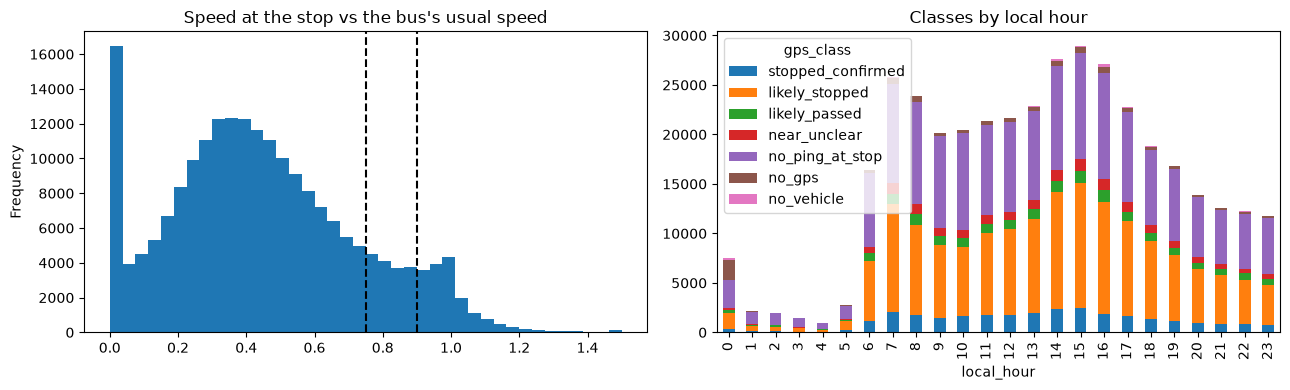

In [10]:
near = stop_gps[stop_gps["n_near"] > 0]
print(f"calls with a ping within {NEAR_M} m of the stop: {len(near):,} of {len(stop_gps):,} ({len(near) / len(stop_gps):.1%})")
print("\nslowest speed (m/s) among the pings at the stop, for those calls:")
print(near["slowest_near_ms"].describe(percentiles=[.1, .25, .5, .75, .9]).round(2).to_string())
print("\nsame as a share of the bus's usual speed:")
print(near["slowest_near_ratio"].describe(percentiles=[.1, .25, .5, .75, .9]).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
near["slowest_near_ratio"].dropna().clip(upper=1.5).plot(kind="hist", bins=40, ax=ax[0],
                                                         title="Speed at the stop vs the bus's usual speed")
ax[0].axvline(SLOW_RATIO, color="k", ls="--"); ax[0].axvline(FAST_RATIO, color="k", ls="--")
(pd.crosstab(stop_gps["local_hour"], stop_gps["gps_class"]).reindex(columns=ORDER, fill_value=0)
   .plot(kind="bar", stacked=True, ax=ax[1], title="Classes by local hour"))
plt.tight_layout()
plt.show()

In [11]:
# Per stop. These are counts of evidence, not probabilities: a bus that stands still is much more likely to be
# caught by a ping near the stop than one that drives past, so "stopped" is over-represented in these counts.
# Compare stops with each other, do not read the shares as exact.
g = stop_gps.assign(stopped=stop_gps["gps_class"].isin(["stopped_confirmed", "likely_stopped"]),
                    passed=stop_gps["gps_class"].eq("likely_passed")).groupby("stop_id")
per_stop = g.agg(calls=("gps_class", "size"), stopped=("stopped", "sum"), passed=("passed", "sum")).reset_index()
per_stop = per_stop.merge(stops[["stop_id", "stop_name"]], on="stop_id", how="left")
per_stop["conclusive"] = per_stop["stopped"] + per_stop["passed"]
per_stop["passed_share"] = (per_stop["passed"] / per_stop["conclusive"]).round(3)

print("stops where buses most often drove past (at least 10 conclusive calls):")
display(per_stop[per_stop["conclusive"] >= 10].sort_values("passed_share", ascending=False).head(15))


def show_trip(service_date, trip_id):
    # call-by-call result of one trip, to check against what you know of the route
    d = stop_gps[(stop_gps["service_date"] == service_date) & (stop_gps["trip_id"] == trip_id)].sort_values("stop_sequence")
    return d[["stop_sequence", "stop_name", "visit_time", "vehicle_id", "min_dist_m", "n_near", "slowest_near_ms", "slowest_near_ratio", "gps_class"]]


first_trip = stop_gps[["service_date", "trip_id"]].drop_duplicates().iloc[0]
display(show_trip(first_trip["service_date"], first_trip["trip_id"]))

stops where buses most often drove past (at least 10 conclusive calls):


,stop_id,calls,stopped,passed,stop_name,conclusive,passed_share
1646,NSR:Quay:45878,74,0,14,Visteveien 25,14,1.000
2032,NSR:Quay:46359,73,1,14,Meland,15,0.933
2076,NSR:Quay:46416,107,1,14,Merland,15,0.933
2578,NSR:Quay:47094,103,1,13,Lutsiskog,14,0.929
2043,NSR:Quay:46370,73,1,12,Nedre Øksnavad,13,0.923
2684,NSR:Quay:47219,73,1,11,Storhaug,12,0.917
2685,NSR:Quay:47220,76,1,9,Storhaug,10,0.900
2075,NSR:Quay:46415,112,2,13,Merland,15,0.867
3519,NSR:Quay:48328,73,2,13,Postvegen,15,0.867
1982,NSR:Quay:46289,114,4,22,Maudvegen,26,0.846


,stop_sequence,stop_name,visit_time,vehicle_id,min_dist_m,n_near,slowest_near_ms,slowest_near_ratio,gps_class
0,1,Jernbaneveien,2026-11-12 04:47:39.311000000+00:00,4063,5.206689,2,0.012141,0.002393,stopped_confirmed
1,2,Stavanger politistasjon,2026-11-12 04:49:13.307000000+00:00,4063,13.746503,1,1.441235,0.155241,likely_stopped
2,3,Statens hus,2026-11-12 04:49:43.318000000+00:00,4063,131.012534,0,NaN,NaN,no_ping_at_stop
3,4,Vålandsbakken,2026-11-12 04:50:18.306000000+00:00,4063,82.889156,0,NaN,NaN,no_ping_at_stop
4,5,Lindahlsbakken,2026-11-12 04:50:40.297000000+00:00,4063,143.718504,0,NaN,NaN,no_ping_at_stop
5,6,Strømsbrua,2026-11-12 04:51:27.313000000+00:00,4063,2.755753,1,2.558652,0.306065,likely_stopped
6,7,Hillevågstunnelen,2026-11-12 04:52:49.319000000+00:00,4063,6.515108,1,1.432714,0.155104,likely_stopped
7,8,Hillevåg,2026-11-12 04:53:40.311000000+00:00,4063,7.194649,1,3.774654,0.514515,likely_stopped
8,9,Kvaleberg skole,2026-11-12 04:54:37.314000000+00:00,4063,88.313314,0,NaN,NaN,no_ping_at_stop
9,10,Sjøhagen,2026-11-12 04:56:02.327000000+00:00,4063,6.462028,2,0.006924,0.000843,stopped_confirmed


## 7b. Evidence along the route (v6)

v5 only counts a ping that lands within `NEAR_M` of the stop, so 43% of calls end up as `no_ping_at_stop`. Here every call gets evidence from the **ping interval that surrounds the stop**, measured **along the route** (GTFS shape, or the stop-to-stop line if there is no shape):

1. Each ping is snapped to the route, giving a distance along the route `s`. Jitter that makes `s` go backwards is removed (isotonic regression), because a bus does not drive backwards.
2. For each ping interval: `time_lost = (time between the pings) - (distance covered / the bus's usual speed)`. A bus that stood at a stop inside the interval loses time.
3. The same number is computed for ping intervals that contain **no stop** (traffic lights, turns, congestion stay in that comparison). `p_excess` = share of stop-free intervals that lost at least as much time as this stop. Low = looks like a stop. High = no stop-like time loss, which is **not** proof of "passed".
4. Linear interpolation gives the time the bus enters and leaves the stop zone (`R_STOP_M` along the route). Compared with the feed's `visit_time`, that tells whether the ET time is arrival or departure, and how accurate it is.

### Comparing the feed with GPS

The feed's `call_type == "recorded"` means ET marked the call as recorded; it does not prove that the bus physically stopped. For a side-by-side comparison, 7b marks a GPS call as **stop-like** when `p_excess <= 0.05`. This means its delay is rare among stop-free intervals, not that there is a 95% probability the bus stopped. **ET only** means ET marked it recorded but GPS did not find unusually high delay; **GPS only** means GPS found unusually high delay but ET did not mark it recorded. These are disagreements between indicators, not proof either method is wrong. The comparison also shows how the older nearby-ping classes compare. `likely_passed` is not treated as the opposite of a recorded call: a bus can pass a stop when nobody needs service.

I tested Newton and monotone-cubic interpolation against plain linear on simulated data: no accuracy gain at 30 s pings, so only linear is used. `dwell_s` is not estimated: a 10-20 s stop between two pings cannot be seen.

In [12]:
# ---- v6 parameters (MAX_GAP_S, MIN_DT_S and the CRUISE_* settings come from the setup cell) ----
from scipy.stats import ks_2samp

R_STOP_M = 25              # "at the stop" = within this many metres ALONG the route
ANCHOR_WIN_M = 600         # a ping is snapped only to the route part where the ET times say the bus is (handles loops)
MAX_OFFROUTE_SHAPE = 60    # drop pings further than this (m) from the GTFS shape
MAX_OFFROUTE_STOPS = 150   # same when the route is only the stop-to-stop polyline (coarser)
MAX_STOP_OFFROUTE_M = 100  # a stop further than this from its route is not used
PAD_S = 120                # use pings this many seconds before the first / after the last recorded call
MIN_PINGS = 5              # shortest unbroken ping chunk that is used
MIN_NULL = 500             # fewer stop-free intervals than this: p_excess is not reliable


def clean_poly(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    keep = np.r_[True, np.hypot(np.diff(x), np.diff(y)) > 0.5]
    x, y = x[keep], y[keep]
    if len(x) < 2:
        return None
    return x, y, np.r_[0.0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]


def project(px, py, poly, lo=None, hi=None):
    """Snap points to a polyline; lo/hi = allowed along-route window per point (m).
    Returns distance along the route and distance from the route."""
    x, y, cum = poly
    ax, ay, dx, dy = x[:-1], y[:-1], np.diff(x), np.diff(y)
    L2 = dx * dx + dy * dy
    u = np.clip(((px[:, None] - ax) * dx + (py[:, None] - ay) * dy) / L2, 0.0, 1.0)
    d2 = (px[:, None] - (ax + u * dx)) ** 2 + (py[:, None] - (ay + u * dy)) ** 2
    if lo is not None:
        d2 = np.where((cum[1:][None, :] >= lo[:, None]) & (cum[:-1][None, :] <= hi[:, None]), d2, np.inf)
    k = np.argmin(d2, axis=1)
    r = np.arange(len(px))
    return cum[k] + u[r, k] * np.sqrt(L2[k]), np.sqrt(d2[r, k])


def project_stops(sx, sy, poly):
    """Stops in trip order, each snapped at or after the previous one."""
    s, off = np.full(len(sx), np.nan), np.full(len(sx), np.nan)
    prev = 0.0
    for i in range(len(sx)):
        si, di = project(sx[i:i + 1], sy[i:i + 1], poly, lo=np.array([prev - 1.0]), hi=np.array([np.inf]))
        off[i] = di[0]
        if di[0] <= MAX_STOP_OFFROUTE_M:
            s[i], prev = si[0], si[0]
    return s, off


def pav(y):
    """Isotonic (non-decreasing) regression, pool-adjacent-violators."""
    vals, wts = [], []
    for v in y:
        vals.append(float(v)); wts.append(1)
        while len(vals) > 1 and vals[-2] > vals[-1]:
            v2, w2 = vals.pop(), wts.pop()
            vals[-1] = (vals[-1] * wts[-1] + v2 * w2) / (wts[-1] + w2)
            wts[-1] += w2
    return np.repeat(vals, wts)


def thin(t):
    keep, last = [], -np.inf
    for i, v in enumerate(t):
        if v - last >= MIN_DT_S:
            keep.append(i); last = v
    return np.array(keep, int)


def load_polylines(trip_ids):
    """trip_id -> (polyline, "shape" | "stops"). Shape if the GTFS has one, otherwise the stop-to-stop line."""
    trips_full = pd.read_parquet(pq_path("gtfs_trips"))
    polys = {}
    if "shape_id" in trips_full.columns and pq_path("gtfs_shapes").exists():
        shape_of = trips_full.drop_duplicates("trip_id").set_index("trip_id")["shape_id"].reindex(trip_ids)
        sh = pd.read_parquet(pq_path("gtfs_shapes"))
        sh = sh[sh["shape_id"].isin(set(shape_of.dropna()))].copy()
        for c in ["shape_pt_lat", "shape_pt_lon", "shape_pt_sequence"]:
            sh[c] = pd.to_numeric(sh[c], errors="coerce")
        sh = sh.dropna(subset=["shape_pt_lat", "shape_pt_lon", "shape_pt_sequence"]).sort_values(["shape_id", "shape_pt_sequence"])
        by_shape = {}
        for sid, d in sh.groupby("shape_id", sort=False):
            p = clean_poly(*to_xy(d["shape_pt_lat"], d["shape_pt_lon"]))
            if p is not None:
                by_shape[sid] = p
        polys = {t: (by_shape[sid], "shape") for t, sid in shape_of.items() if sid in by_shape}
    missing = [t for t in trip_ids if t not in polys]
    if missing:
        stt = st_all[st_all["trip_id"].isin(set(missing))].merge(stops[["stop_id", "stop_lat", "stop_lon"]], on="stop_id", how="left")
        for t, d in stt.dropna(subset=["stop_lat", "stop_lon"]).sort_values(["trip_id", "stop_sequence"]).groupby("trip_id", sort=False):
            p = clean_poly(*to_xy(d["stop_lat"], d["stop_lon"]))
            if p is not None:
                polys[t] = (p, "stops")
    print(f"route geometry: {sum(v[1] == 'shape' for v in polys.values()):,} trips from GTFS shapes, "
          f"{sum(v[1] == 'stops' for v in polys.values()):,} from the stop-to-stop line, "
          f"{len(trip_ids) - len(polys):,} without any")
    return polys

In [13]:
def trip_evidence(g, trk, poly_src):
    """One trip: along-route position of the bus, time lost around each stop, and the stop-free intervals."""
    n = len(g)
    cols = ["s_stop_m", "stop_offroute_m", "gps_enter_t", "gps_leave_t", "local_gap_s", "time_lost_s"]
    out = {c: np.full(n, np.nan) for c in cols}
    status = np.full(n, "not_covered", dtype=object)
    null = []

    def done():
        d = g[["service_date", "trip_id", "stop_id", "stop_sequence", "vehicle_id", "visit_time"]].copy()
        for c in cols:
            d[c] = out[c]
        d["route_status"] = status
        d["geom_src"] = poly_src[1] if poly_src else None
        return d, null

    if poly_src is None:
        status[:] = "no_route_geometry"; return done()
    poly, src = poly_src
    if trk is None:
        status[:] = "no_vehicle_track"; return done()

    s_stop, off_stop = project_stops(g["x"].to_numpy(), g["y"].to_numpy(), poly)
    out["s_stop_m"], out["stop_offroute_m"] = s_stop, off_stop
    T = g["T"].to_numpy(float)
    ok = ~np.isnan(s_stop) & ~np.isnan(T)
    status[np.isnan(s_stop)] = "stop_offroute"
    if ok.sum() < 3:
        return done()
    aT, aS = np.maximum.accumulate(T[ok]), s_stop[ok]
    T_first, T_last = T[ok].min(), T[ok].max()

    t_all, x_all, y_all = trk[:3]
    i0, i1 = np.searchsorted(t_all, [T_first - PAD_S, T_last + PAD_S])
    t, x, y = t_all[i0:i1], x_all[i0:i1], y_all[i0:i1]
    if len(t) < MIN_PINGS:
        status[ok] = "few_pings"; return done()
    exp_s = np.interp(t, aT, aS)       # rough position from the ET times, only used to pick the right part of the route
    s_raw, off = project(x, y, poly, lo=exp_s - ANCHOR_WIN_M, hi=exp_s + ANCHOR_WIN_M)
    good = off <= (MAX_OFFROUTE_SHAPE if src == "shape" else MAX_OFFROUTE_STOPS)
    t, s_raw = t[good], s_raw[good]
    k = thin(t) if len(t) else np.array([], int)
    t, s_raw = t[k], s_raw[k]
    if len(t) < MIN_PINGS:
        status[ok] = "few_pings"; return done()

    s_iso = pav(s_raw)
    bounds = np.r_[0, np.where(np.diff(t) > MAX_GAP_S)[0] + 1, len(t)]       # never bridge a GPS hole
    stop_s_sorted = s_stop[~np.isnan(s_stop)]
    assigned = np.zeros(n, bool)
    any_chunk = False
    for a, b in zip(bounds[:-1], bounds[1:]):
        if b - a < MIN_PINGS:
            continue
        any_chunk = True
        tc, sc = t[a:b], s_iso[a:b]
        dt_p, ds_p = np.diff(tc), np.diff(sc)
        cr = pd.Series(ds_p / dt_p).rolling(CRUISE_WIN, center=True, min_periods=5).quantile(CRUISE_Q).to_numpy()
        cr = np.where(cr >= MIN_CRUISE_MS, cr, np.nan)
        loss = dt_p - ds_p / cr                                               # seconds lost vs the bus's usual speed
        has_stop = (np.searchsorted(stop_s_sorted, sc[1:] + R_STOP_M, "right")
                    - np.searchsorted(stop_s_sorted, sc[:-1] - R_STOP_M, "left")) > 0
        in_trip = (tc[:-1] >= T_first) & (tc[1:] <= T_last)
        null.append(loss[~has_stop & in_trip & np.isfinite(loss)])            # intervals with no stop inside

        for i in np.where(ok & ~assigned)[0]:
            s0 = s_stop[i]
            if not (sc[0] - R_STOP_M <= s0 <= sc[-1] + R_STOP_M):
                continue
            touch = (sc[1:] >= s0 - R_STOP_M) & (sc[:-1] <= s0 + R_STOP_M)
            if touch.any() and np.isfinite(loss[touch]).any():
                out["time_lost_s"][i] = float(np.nanmax(loss[touch]))
            ie = int(np.searchsorted(sc, s0 - R_STOP_M, "left"))               # linear interpolation of enter / leave time
            if 0 < ie < len(sc):
                out["gps_enter_t"][i] = tc[ie - 1] + (s0 - R_STOP_M - sc[ie - 1]) / (sc[ie] - sc[ie - 1]) * (tc[ie] - tc[ie - 1])
                out["local_gap_s"][i] = tc[ie] - tc[ie - 1]
            il = int(np.searchsorted(sc, s0 + R_STOP_M, "right"))
            if 0 < il < len(sc):
                out["gps_leave_t"][i] = tc[il - 1] + (s0 + R_STOP_M - sc[il - 1]) / (sc[il] - sc[il - 1]) * (tc[il] - tc[il - 1])
            status[i] = "ok"
            assigned[i] = True
    if not any_chunk:
        status[ok] = "gps_gap"
    return done()


calls = stop_gps[stop_gps["vehicle_id"].notna()]
polys = load_polylines(list(calls["trip_id"].unique()))
route_parts, null_parts = [], []
for _, g in calls.groupby(["service_date", "trip_id"], sort=False):
    g = g.sort_values("stop_sequence")
    d, nl = trip_evidence(g, tracks.get(g["route_id"].iloc[0], {}).get(g["vehicle_id"].iloc[0]), polys.get(g["trip_id"].iloc[0]))
    route_parts.append(d)
    null_parts.extend(nl)
route_ev = pd.concat(route_parts, ignore_index=True)
null = np.sort(np.concatenate(null_parts)) if null_parts else np.array([])
print(f"{len(route_ev):,} calls processed | {len(null):,} stop-free ping intervals for the comparison")

route geometry: 7,819 trips from GTFS shapes, 0 from the stop-to-stop line, 0 without any
380,552 calls processed | 242,101 stop-free ping intervals for the comparison


In [14]:
# ---- turn the numbers into columns ----
visit_s = (pd.to_datetime(route_ev["visit_time"], utc=True) - EPOCH).dt.total_seconds()
route_ev["ts_offset_enter_s"] = route_ev["gps_enter_t"] - visit_s     # ET time vs the bus entering the stop zone
route_ev["ts_offset_leave_s"] = route_ev["gps_leave_t"] - visit_s     # ET time vs the bus leaving it
route_ev["gps_enter_time"] = pd.to_datetime(route_ev["gps_enter_t"], unit="s", utc=True)
route_ev["gps_leave_time"] = pd.to_datetime(route_ev["gps_leave_t"], unit="s", utc=True)
if len(null):
    ge = len(null) - np.searchsorted(null, route_ev["time_lost_s"].to_numpy(), "left")
    route_ev["p_excess"] = np.where(route_ev["time_lost_s"].notna(), (ge + 1) / (len(null) + 1), np.nan)
else:
    route_ev["p_excess"] = np.nan
route_ev = route_ev.drop(columns=["gps_enter_t", "gps_leave_t"])

print("status of the calls:")
print(route_ev["route_status"].value_counts().to_string())
okr = route_ev[route_ev["route_status"] == "ok"]
for lab, c in [("enters", "ts_offset_enter_s"), ("leaves", "ts_offset_leave_s")]:
    print(f"\nGPS time the bus {lab} the stop zone minus ET visit_time (s): median {okr[c].median():.1f}, "
          f"p10 {okr[c].quantile(.1):.1f}, p90 {okr[c].quantile(.9):.1f}")
print("-> the offset that is tighter around 0 tells you whether ET records arrival or departure")
print(f"median ping spacing around the stop: {okr['local_gap_s'].median():.0f} s")

tl = okr["time_lost_s"].dropna()
if len(null) < MIN_NULL:
    print(f"\nWARNING: only {len(null)} stop-free intervals; time_lost / p_excess is NOT reliable "
          "(stops are too dense relative to the ping spacing).")
if len(tl) and len(null):
    ks = ks_2samp(tl, null)
    print(f"\ntime_lost  stops: median {tl.median():.1f}s (n={len(tl):,}) | stop-free: median {np.median(null):.1f}s (n={len(null):,})")
    print(f"KS test stops vs stop-free: D={ks.statistic:.3f}, p={ks.pvalue:.2g}")
    print(f"share of calls with p_excess <= 0.05: {(okr['p_excess'] <= 0.05).mean():.1%} (about 5% if stops looked like stop-free intervals)")

# what v5 could not say: how many of its blind-spot calls now have evidence?
new_cols = ["route_status", "geom_src", "s_stop_m", "stop_offroute_m", "local_gap_s", "time_lost_s", "p_excess",
            "ts_offset_enter_s", "ts_offset_leave_s", "gps_enter_time", "gps_leave_time"]
KEY3 = ["service_date", "trip_id", "stop_sequence"]
n0 = len(stop_gps)
stop_gps = stop_gps.drop(columns=[c for c in new_cols if c in stop_gps.columns]).merge(route_ev[KEY3 + new_cols], on=KEY3, how="left")
assert len(stop_gps) == n0, "merge multiplied rows: check duplicate (service_date, trip_id, stop_sequence)"
cover = (stop_gps.groupby("gps_class")["time_lost_s"].apply(lambda s: s.notna().mean()).reindex(ORDER).round(3)
         .to_frame("share_with_time_lost"))
print("\nshare of each v5 class that now has a time_lost value:")
display(cover)

# Compare ET's recorded-call flag with the 7b route-delay signal.
comparison = stop_gps[["service_date", "trip_id", "stop_sequence", "stop_name", "call_type",
                       "gps_class", "route_status", "time_lost_s", "p_excess"]].copy()
et_call_type = comparison["call_type"].astype("string").str.strip().str.lower()
et_known = (et_call_type.notna() & et_call_type.ne("")).fillna(False)
comparison["et_recorded"] = et_call_type.eq("recorded").fillna(False)
gps_7b_known = comparison["route_status"].eq("ok") & comparison["p_excess"].notna()
comparison["gps_7b_stop_like"] = comparison["p_excess"].le(0.05)
paired = comparison.loc[et_known & gps_7b_known].copy()

paired["agreement"] = np.select(
    [paired["et_recorded"] & paired["gps_7b_stop_like"],
     paired["et_recorded"] & ~paired["gps_7b_stop_like"],
     ~paired["et_recorded"] & paired["gps_7b_stop_like"]],
    ["both", "ET only", "GPS only"], default="neither flagged")
AGREEMENT_ORDER = ["both", "ET only", "GPS only", "neither flagged"]
agreement_counts = paired["agreement"].value_counts().reindex(AGREEMENT_ORDER, fill_value=0)
comparison_summary = pd.Series({
    "Calls with both methods available": len(paired),
    "ET marked recorded": int(paired["et_recorded"].sum()),
    "GPS stop-like delay (p_excess <= 0.05)": int(paired["gps_7b_stop_like"].sum()),
    "Both methods say yes": int(agreement_counts["both"]),
    "ET only": int(agreement_counts["ET only"]),
    "GPS only": int(agreement_counts["GPS only"]),
    "Neither threshold flags the call": int(agreement_counts["neither flagged"]),
    "Union (either method says yes)": int(paired["et_recorded"].sum() + paired["gps_7b_stop_like"].sum() - agreement_counts["both"]),
    "Disagreement (ET only + GPS only)": int(agreement_counts["ET only"] + agreement_counts["GPS only"]),
}, name="calls").to_frame()
print("\nET recorded-call vs 7b GPS stop-like comparison (paired calls only):")
display(comparison_summary)

daily_agreement = (paired.groupby(["service_date", "agreement"]).size().unstack(fill_value=0)
                   .reindex(columns=AGREEMENT_ORDER, fill_value=0))
daily_agreement["paired_calls"] = daily_agreement[AGREEMENT_ORDER].sum(axis=1)
daily_agreement["union"] = daily_agreement[["both", "ET only", "GPS only"]].sum(axis=1)
daily_agreement["disagreement"] = daily_agreement[["ET only", "GPS only"]].sum(axis=1)
print("\nAgreement and disagreement by service date:")
display(daily_agreement)

ping_compare = comparison.loc[et_known].copy()
ping_compare["ET status"] = np.where(ping_compare["et_recorded"], "ET recorded", "ET not marked recorded")
ping_class_comparison = pd.crosstab(ping_compare["ET status"], ping_compare["gps_class"])
print("\nET status vs the nearby-ping GPS classes (classes such as no_gps/no_vehicle are not stop decisions):")
display(ping_class_comparison)

not_available = pd.Series({
    "Observed calls in GPS results": len(comparison),
    "ET call_type available": int(et_known.sum()),
    "7b GPS result available": int(gps_7b_known.sum()),
    "Both methods available": len(paired),
}, name="calls").to_frame()
print("\nComparison coverage (missing method results are excluded from agreement counts):")
display(not_available)

mismatch_examples = paired[paired["agreement"].isin(["ET only", "GPS only"])]
mismatch_examples = mismatch_examples[["service_date", "trip_id", "stop_sequence", "stop_name", "call_type",
                                       "gps_class", "time_lost_s", "p_excess", "agreement"]].head(20)
print("\nExample calls where ET and 7b differ:")
display(mismatch_examples)

status of the calls:
route_status
ok               367423
not_covered       11148
stop_offroute      1948
few_pings            30
gps_gap               3

GPS time the bus enters the stop zone minus ET visit_time (s): median -8.8, p10 -25.8, p90 -3.5

GPS time the bus leaves the stop zone minus ET visit_time (s): median -1.0, p10 -11.1, p90 1.3
-> the offset that is tighter around 0 tells you whether ET records arrival or departure
median ping spacing around the stop: 30 s

time_lost  stops: median 10.0s (n=366,851) | stop-free: median 1.7s (n=242,101)
KS test stops vs stop-free: D=0.295, p=0
share of calls with p_excess <= 0.05: 15.3% (about 5% if stops looked like stop-free intervals)

share of each v5 class that now has a time_lost value:


,share_with_time_lost
gps_class,
stopped_confirmed,0.937
likely_stopped,0.989
likely_passed,0.994
near_unclear,0.992
no_ping_at_stop,0.986
no_gps,0.120
no_vehicle,0.000



ET recorded-call vs 7b GPS stop-like comparison (paired calls only):


,calls
Calls with both methods available,366851
ET marked recorded,366831
GPS stop-like delay (p_excess <= 0.05),56246
Both methods say yes,56245
ET only,310586
GPS only,1
Neither threshold flags the call,19
Union (either method says yes),366832
Disagreement (ET only + GPS only),310587



Agreement and disagreement by service date:


agreement,both,ET only,GPS only,neither flagged,paired_calls,union,disagreement
service_date,,,,,,,
2026-11-12,21808,120051,1,19,141879,141860,120052
2026-11-13,21699,118109,0,0,139808,139808,118109
2026-11-14,12489,70905,0,0,83394,83394,70905
2026-11-15,249,1521,0,0,1770,1770,1521


... (2 outputs left out)


Comparison coverage (missing method results are excluded from agreement counts):


,calls
Observed calls in GPS results,381796
ET call_type available,381796
7b GPS result available,366851
Both methods available,366851



Example calls where ET and 7b differ:


,service_date,trip_id,stop_sequence,stop_name,call_type,gps_class,time_lost_s,p_excess,agreement
2,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,3,Statens hus,recorded,no_ping_at_stop,-2.768586,0.823492,ET only
3,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,4,Vålandsbakken,recorded,no_ping_at_stop,-4.641125,0.879034,ET only
4,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,5,Lindahlsbakken,recorded,no_ping_at_stop,-3.408282,0.845805,ET only
5,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,6,Strømsbrua,recorded,likely_stopped,20.998634,0.057331,ET only
7,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,8,Hillevåg,recorded,likely_stopped,12.966971,0.146810,ET only
8,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,9,Kvaleberg skole,recorded,no_ping_at_stop,-2.874720,0.827548,ET only
10,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,11,Eikeberg,recorded,likely_stopped,19.601070,0.067662,ET only
13,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,14,Hinnasvingene,recorded,likely_stopped,14.559742,0.121697,ET only
14,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,15,Skråtårnet,recorded,likely_stopped,14.244497,0.126323,ET only
15,2026-11-12,KOL:ServiceJourney:1001_251008118343317_1001,16,Stadionparken,recorded,near_unclear,5.583823,0.332583,ET only


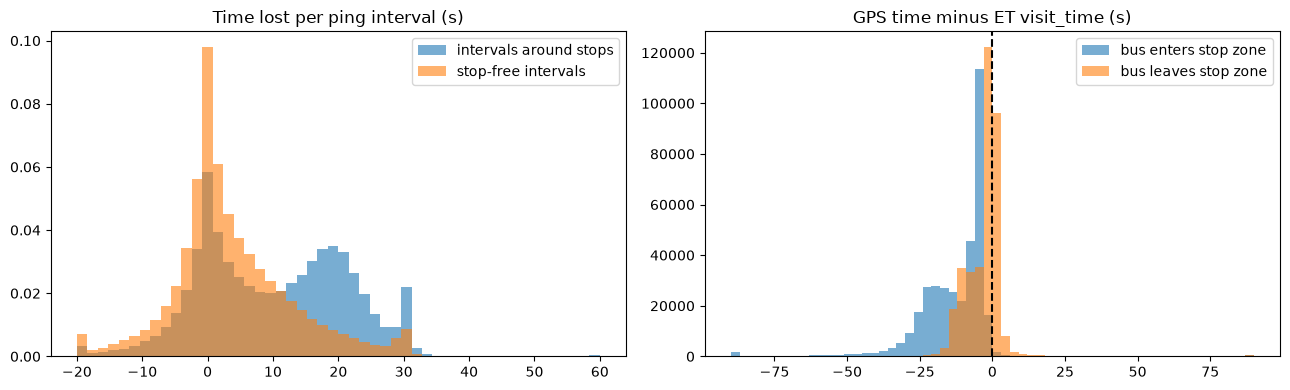

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
lo, hi = -20, 60
ax[0].hist(np.clip(okr["time_lost_s"].dropna(), lo, hi), bins=50, range=(lo, hi), density=True, alpha=.6, label="intervals around stops")
ax[0].hist(np.clip(null, lo, hi), bins=50, range=(lo, hi), density=True, alpha=.6, label="stop-free intervals")
ax[0].set_title("Time lost per ping interval (s)"); ax[0].legend()
for c, lab in [("ts_offset_enter_s", "bus enters stop zone"), ("ts_offset_leave_s", "bus leaves stop zone")]:
    ax[1].hist(np.clip(okr[c].dropna(), -90, 90), bins=60, range=(-90, 90), alpha=.6, label=lab)
ax[1].axvline(0, color="k", ls="--"); ax[1].set_title("GPS time minus ET visit_time (s)"); ax[1].legend()
plt.tight_layout()
plt.show()

## 8. Results stay in memory

In [ ]:
print("Analysis complete. Results remain in notebook memory; no files were written.")

Analysis complete. Results remain in notebook memory; no files were written.


: 

## Limits

- **30-second pings.** A short dwell can fall between two pings, so `no_ping_at_stop` is a blind spot, not a "passed". Only `likely_passed` is evidence of a bus driving past; absence of `stopped` is not.
- **Standing near a stop is not the same as opening the doors.** A bus held at a red light within `NEAR_M` of a stop looks the same as a bus that stopped. Door-open or passenger-count data would settle it; this dataset has neither.
- **Matching depends on the recorded times.** The bus is found by where it was at the feed's actual times, so calls without an actual time (`unconfirmed`, `cancelled`, not in feed) cannot be tested.
- **Thresholds are judgement.** `NEAR_M`, `SLOW_MS`, `SLOW_RATIO` and `FAST_RATIO` are in the setup cell. They were set on simulated data, so check the histogram in section 7 on the real data and move the dashed lines into the gap between the two groups.

- **`p_excess` is a ranking score, not a strict test.** Traffic lights and congestion sit in the stop-free comparison, so it is conservative. "No stop-like time loss" is not proof that the bus drove past.
- **The stop-free comparison needs enough stop-free intervals.** The notebook warns when there are fewer than `MIN_NULL`. It also over-represents the stretches between stops.
- **No dwell time.** A stop of 10-20 s between two ping intervals that look normal cannot be seen by any interpolation; only `time_lost_s` picks it up indirectly. `local_gap_s` shows the ping spacing behind each result.
- **Route geometry.** Without GTFS shapes the route is the stop-to-stop straight line, which is coarser on curves (larger `MAX_OFFROUTE_STOPS`).